# Three-Stage Modeling of HIV Infection and Implications for Antiretroviral Therapy

__Cameron Clarke__, Department of Applied Mathematics and Statistics, Colorado School of Mines, Golden, CO 80403, USA

__Stephen Pankavich__, Department of Applied Mathematics and Statistics, Colorado School of Mines, Golden, CO 80403, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook studies the time to AIDS and the CD4+ T-cell count at 5 and 10 years in the three-stage HIV model analysed by Clarke and Pankavich [[1]][R1]. It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes under a minute.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import hiv3_model as hm

SEED = 2024                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
qlabels = [r'$T(5\ \mathrm{yr})$ (cells/mm$^3$)', r'$T(10\ \mathrm{yr})$ (cells/mm$^3$)', r'$F$, time to AIDS (years)']


def order(v):
    """Order of magnitude of a rounding-level value (4.7e-13 -> '1e-13'); such values change between platforms."""
    return f'1e{int(np.floor(np.log10(abs(v))))}' if v != 0 else '0'

### Summary

Clarke and Pankavich [[1]][R1] study a five-equation within-host model of HIV in which infected macrophages act as a long-lived reservoir, so that one set of constant parameters produces the acute stage, the chronic stage and the transition to AIDS, and they use gradient-based active subspaces to find which of its 15 parameters control the T-cell count at 5 and 10 years and the time to AIDS. We reimplement the model in Python with exact forward-sensitivity gradients, draw 1000 Monte Carlo samples from the paper's ±10 % box, and find a dominant one-dimensional active subspace for each output ($\lambda_1/\lambda_2 = 103$, 43.5 and 127.7 for $T(5)$, $T(10)$ and $F$). The first eigenvectors match the published weights of the paper's Fig. 6 with cosines 0.9990, 0.9996 and 0.9921; the largest gap is the weight of $\rho_M$ for the time to AIDS (−0.434 here, about −0.52 in the figure), and capping $F$ at 10 years, as the paper's Fig. 6c inset does, does not close it (−0.439).

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015 [[2]][R2].

### The model

The model is that of Hernandez-Vargas and Middleton [[3]][R3], as written in [[1]][R1], Eq. (1), p. 5:

$$
\begin{aligned}
\dot T &= s_T + \frac{\rho_T V}{c_T + V}\,T - k_T T V - \delta_T T, &
\dot T^* &= k_T T V - \delta_{T^*} T^*,\\
\dot M &= s_M + \frac{\rho_M V}{c_M + V}\,M - k_M M V - \delta_M M, &
\dot M^* &= k_M M V - \delta_{M^*} M^*,\\
\dot V &= p_T T^* + p_M M^* - \delta_V V,
\end{aligned}
$$

where $T$ and $T^*$ are uninfected and infected CD4+ T cells, $M$ and $M^*$ uninfected and infected macrophages (cells/mm³), and $V$ free virus. Time is in days. The paper fixes $T(0) = 10^3$ cells/mm³, $M(0) = 150$ cells/mm³, $T^*(0) = M^*(0) = 0$ and $V(0) = 10$ copies/ml (p. 6), and solves with MATLAB's `ode23s` (p. 6).

**Choices of this data set** (not stated in the paper):
- *Units of V(0).* Table 1 gives $c_T$ and $c_M$ in copies/mm³, so we convert the printed $V(0) = 10$ copies/ml to $0.01$ copies/mm³. With this reading the nominal run reaches $T = 200$ at 7.105 years and $V = 5000$ at 8.615 years; with $V(0) = 10$ copies/mm³ these become 7.031 and 8.541 years (`check_accuracy.py`, check 5). Reading the paper's curves by pixel position gives about 7.1 years for the crossing in Fig. 1 (p. 3) and 8.6 years for $V = 5000$ in Fig. 4 (p. 8), which favours the converted value. The choice hardly changes the gradient directions: at the nominal point the normalized gradients for the two readings have cosines of 0.9998 or more (check 5).
- *Years.* $T(5)$ and $T(10)$ are taken at 1825 and 3650 days (365 days per year); with 365.25 the nominal $F$ changes from 7.1052 to 7.1004 years (check 6).
- *Solver.* `scipy.integrate.solve_ivp`, LSODA, rtol = atol = $10^{-10}$, analytic Jacobian.

**Quantities of interest** (p. 12): the T-cell counts $T(5;\mathbf p)$ and $T(10;\mathbf p)$ after 5 and 10 years, and the time to AIDS

$$F(\mathbf p) = \max\{t \ge 0 : T(t;\mathbf p) > 200\},$$

in years. We locate $F$ as the last downward crossing of $T = 200$ in a 40-year window and raise an error if $T$ is above 200 at the end of the window. The maximum in the definition matters: 28 of the 1000 samples dip below 200 during the acute phase (lowest $T$ 166.2) and recover before the final decline (check 7).

**Gradients.** Exact up to the ODE tolerance: the sensitivities $\partial\mathbf y/\partial\ln p_j$ (75 equations) are integrated with the states. At the crossing, $\partial F/\partial p_j = -(\partial T/\partial p_j)/\dot T$.

**Inputs** (Table 1, p. 6): all 15 parameters, independent and uniform on the printed ranges of ±10 % around the nominal values (Appendix B, p. 37). The printed ranges are rounded (e.g. $k_T$: 4.11–5.02 × 10⁻⁵ for 0.9 and 1.1 × 4.57 × 10⁻⁵), and we use them as printed.

**How this differs from `HIV_Long_Term_Dynamics`.** That data set in this repository is the seven-equation model of Loudon and Pankavich [[4]][R4] (latently infected T cells and cytotoxic T lymphocytes as well as macrophages), with 27 parameters on ±2.5 % ranges and the T-cell count at 19 times as outputs. The model here has five equations (no latent T cells, no immune response; the virus drives the proliferation of T cells and macrophages through Michaelis–Menten terms), 15 parameters on ±10 % ranges, the time to AIDS as an extra output, exact sensitivity gradients, and a new seeded design.

The cell below prints the input table from the model module and repeats three numerical checks the paper reports: the reproduction numbers of Theorem 3 (p. 10) and the limits of the reduced systems in Fig. 5 (p. 11).

In [2]:
print(f"{'#':>2s} {'name':8s} {'units':16s} {'nominal':>9s} {'lower':>9s} {'upper':>9s}  description (Table 1, p. 6)")
for j, n in enumerate(hm.NAMES):
    print(f'{j + 1:2d} {n:8s} {hm.UNITS[j]:16s} {hm.NOMINAL[j]:9.4g} {hm.LOWER[j]:9.4g} {hm.UPPER[j]:9.4g}  {hm.DESCRIPTIONS[j]}')
print(f'\ninitial state (T, T*, M, M*, V)(0) = {hm.Y0.tolist()}; 1 year = {hm.DAYS_PER_YEAR:g} days; '
      f'LSODA rtol = {hm.RTOL:g}, atol = {hm.ATOL:g}; window {hm.HORIZON_YEARS:g} years')
RT, RM = hm.reproduction_numbers(hm.NOMINAL)
print(f'R_T = {RT:.4f}, R_M = {RM:.4f} at the nominal values (paper p. 10: R_T = 1.809, R_M = 0.09)')
f0 = hm.qoi(hm.NOMINAL)
print(f'nominal: T(5 yr) = {f0[0]:.3f}, T(10 yr) = {f0[1]:.4f} cells/mm^3, F = {f0[2]:.4f} years')
# Fig. 5 (p. 11): with p_M = 0 the solution tends to T = 552, V = 283; with p_T = 0 to T = 1000, V = 0
for j, label in [(5, 'p_M = 0'), (4, 'p_T = 0')]:
    p = hm.NOMINAL.copy()
    p[j] = 1e-300                                        # the module requires positive parameters
    y = hm.trajectory(p, [0.0, 200 * 365.0])[:, -1]
    print(f'{label}: at 200 years T = {y[0]:.2f}, V = {y[4]:.3g} '
          f'(paper Fig. 5: {"T -> 552, V -> 283" if j == 5 else "T -> 1000, V -> 0"})')

 # name     units              nominal     lower     upper  description (Table 1, p. 6)
 1 sT       cells/mm^3/day          10         9        11  T-cell source
 2 sM       cells/mm^3/day        0.15     0.135     0.165  macrophage source
 3 kT       mm^3/day/copy     4.57e-05  4.11e-05  5.02e-05  T-cell infection rate
 4 kM       mm^3/day/copy     4.33e-08   3.9e-08  4.76e-08  macrophage infection rate
 5 pT       copies/cell/day         38      34.2      41.8  virus production by infected T cells
 6 pM       copies/cell/day         35      31.5      38.5  virus production by infected macrophages
 7 deltaT   1/day                 0.01     0.009     0.011  T-cell death rate
 8 deltaTs  1/day                  0.4      0.36      0.44  infected T-cell death rate
 9 deltaM   1/day                0.001    0.0009    0.0011  macrophage death rate
10 deltaMs  1/day                0.001    0.0009    0.0011  infected macrophage death rate
11 deltaV   1/day                  2.4      2.16      2.

nominal: T(5 yr) = 382.034, T(10 yr) = 1.7536 cells/mm^3, F = 7.1052 years
p_M = 0: at 200 years T = 552.80, V = 283 (paper Fig. 5: T -> 552, V -> 283)
p_T = 0: at 200 years T = 1000.00, V = -9.63e-16 (paper Fig. 5: T -> 1000, V -> 0)


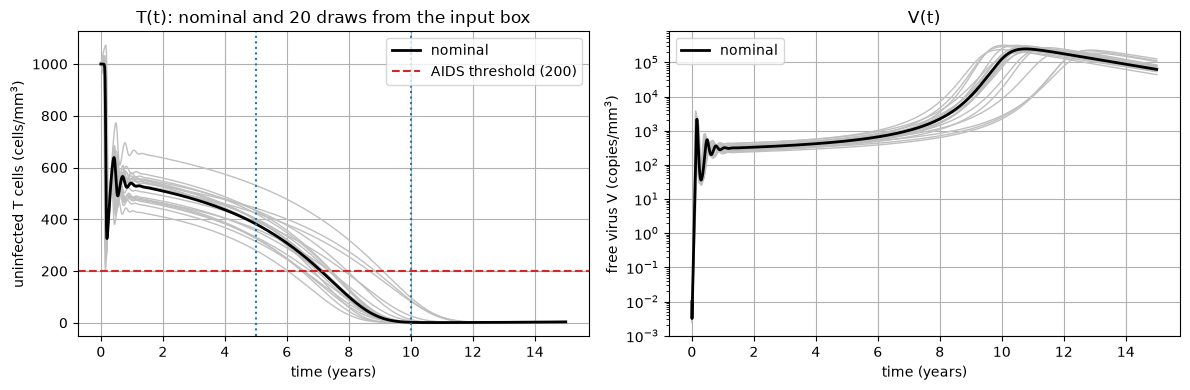

In [3]:
t = np.linspace(0, 15 * 365, 3001)
rng_plot = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for p in hm.LOWER + (hm.UPPER - hm.LOWER) * rng_plot.random((20, 15)):
    y = hm.trajectory(p, t)
    axes[0].plot(t / 365, y[0], color='0.75', lw=1)
    axes[1].semilogy(t / 365, y[4], color='0.75', lw=1)
y = hm.trajectory(hm.NOMINAL, t)
axes[0].plot(t / 365, y[0], 'k', lw=2, label='nominal')
axes[1].semilogy(t / 365, y[4], 'k', lw=2, label='nominal')
axes[0].axhline(hm.T_AIDS, color='C3', ls='--', label='AIDS threshold (200)')
for x in (5, 10):
    axes[0].axvline(x, color='C0', ls=':')
axes[0].set_ylabel('uninfected T cells (cells/mm$^3$)')
axes[1].set_ylabel('free virus V (copies/mm$^3$)')
for ax in axes:
    ax.set_xlabel('time (years)')
    ax.grid(True)
    ax.legend()
axes[0].set_title('T(t): nominal and 20 draws from the input box')
axes[1].set_title('V(t)')
fig.tight_layout()
plt.close(fig)
fig

The module reproduces $R_T = 1.8090$ (paper 1.809) and $R_M = 0.0947$ (paper 0.09, rounded). With $p_M \to 0$ the solution settles at $T = 552.80$, $V = 283$, the values in the caption of Fig. 5; with $p_T \to 0$ it returns to $T = 1000$ with $V$ at round-off level. At the nominal values $T(5) = 382.034$, $T(10) = 1.7536$ cells/mm³ and $F = 7.1052$ years. The figure shows the three stages: the acute dip within the first months, the slow chronic decline, and the fall below 200 between about 5 and 11 years.

### Load data

`generate_data.py` drew $M = 1000$ independent Monte Carlo samples from the uniform box (seed 2024) and wrote the physical inputs, the three outputs, and their gradients with respect to the physical parameters (`DATA.md` gives the run time). We check the files against the model at three samples and the gradients at one sample against central differences in $\ln p$ (step $10^{-5}$, tighter solves).

In [4]:
X = np.loadtxt('inputs.csv', delimiter=',')                        # (M, 15) physical parameters
f = np.loadtxt('outputs.csv', delimiter=',')                       # (M, 3) T5, T10 (cells/mm^3), F (years)
G = np.loadtxt('gradients.csv', delimiter=',').reshape(-1, 3, 15)  # (M, 3, 15) d(T5, T10, F)/dp, physical
print(f'inputs {X.shape}, outputs {f.shape}, gradients {G.shape}')

inputs (1000, 15), outputs (1000, 3), gradients (1000, 3, 15)


In [5]:
rows = [0, 1, 2]
f3 = hm.qois(X[rows])                                   # state-only solves (5 ODEs instead of 80)
print(f'model vs outputs.csv at rows {rows}: max relative difference {np.max(np.abs(f3 - f[rows]) / np.abs(f[rows])):.1e}')
h = 1e-5
p = X[0]
Gfd = np.column_stack([(hm.qoi(p * np.exp(h * e), rtol=1e-12, atol=1e-10) - hm.qoi(p * np.exp(-h * e), rtol=1e-12, atol=1e-10)) / (2 * h)
                       for e in np.eye(15)])
err = np.linalg.norm(Gfd - G[0] * p, axis=1) / np.linalg.norm(G[0] * p, axis=1)
print(f'row 0, gradients vs central differences in ln p (h = {h:g}): relative error T5 {err[0]:.1e}, T10 {err[1]:.1e}, F {err[2]:.1e}')
inside = np.all((X >= hm.LOWER) & (X <= hm.UPPER))
print(f'all samples inside the Table 1 box: {inside}')
for q, n in enumerate(hm.QOI_NAMES):
    print(f'{n}: range [{f[:, q].min():.4g}, {f[:, q].max():.4g}] {hm.QOI_UNITS[q]}, median {np.median(f[:, q]):.4g}')
print(f'samples with T(5 yr) < 200: {(f[:, 0] < 200).sum()}; with T(10 yr) < 200: {(f[:, 1] < 200).sum()}; '
      f'with F < 10 years: {(f[:, 2] < 10).sum()} of {len(f)}')

model vs outputs.csv at rows [0, 1, 2]: max relative difference 8.2e-09


row 0, gradients vs central differences in ln p (h = 1e-05): relative error T5 1.1e-06, T10 3.4e-07, F 6.1e-07
all samples inside the Table 1 box: True
T5: range [186.7, 658.5] cells/mm^3, median 383.6
T10: range [0.5781, 359.3] cells/mm^3, median 2.149
F: range [4.863, 11.5] years, median 7.118
samples with T(5 yr) < 200: 4; with T(10 yr) < 200: 985; with F < 10 years: 985 of 1000


The model reproduces the stored outputs to a relative $8.2\times10^{-9}$ (the check solves 5 equations, the files came from the 80-equation solve with sensitivities, so the two differ at the level of the ODE tolerance), and the gradients agree with central differences to $1.1\times10^{-6}$, the size of the differences' own truncation and solver error. Every sample lies in the box. $T(5)$ ranges over 186.7–658.5 cells/mm³ and only 4 samples are below 200; $T(10)$ is below 200 in 985 samples (median 2.149), and $F$ ranges over 4.863–11.5 years with median 7.118.

### Estimate the subspace

The model is cheap and smooth and we have exact gradients, so we use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates, for each output separately. The input space is `ac.Uniform` on the Table 1 ranges; each input is scaled by its range to $[-1, 1]$, as in the paper's Appendix B (p. 37), and the library converts the physical gradients accordingly. We use 500 bootstrap replicates with `rng=SEED`. The paper notes that each output increases along its first active variable (p. 13), so we orient each eigenvector with `ac.orient(by="covariance")`, which makes the output increase along $\mathbf w_1$ (and $\mathbf w_2$).

In [6]:
space = ac.Uniform(hm.LOWER, hm.UPPER, names=hm.NAMES)
subs = []
for q in range(3):
    sub = ac.active_subspace(space=space, X=X, f=f[:, q], grads=G[:, q], estimator='as', nboot=500,
                             bootstrap_vectors=2, rng=SEED, qoi=hm.QOI_NAMES[q])
    sub = ac.orient(sub, by='covariance', X=X, f=f[:, q], columns=2)
    subs.append(sub)
    lam = sub.eigenvalues
    ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
    print(f'{hm.QOI_NAMES[q]}: lambda_1..5 = {np.array2string(lam[:5], precision=4)}; '
          f'lambda_k/lambda_k+1 (k = 1..4) = {np.array2string(lam[:4] / lam[1:5], precision=1)}; '
          f'gap rule n = {k_hat}; lambda_1 share {lam[0] / lam.sum():.4f}')

T5: lambda_1..5 = [1.7675e+04 1.7164e+02 1.7757e+01 1.2394e+01 9.3490e+00]; lambda_k/lambda_k+1 (k = 1..4) = [103.    9.7   1.4   1.3]; gap rule n = 1; lambda_1 share 0.9878


T10: lambda_1..5 = [1.2698e+04 2.9160e+02 9.1809e+00 4.6789e+00 3.8151e+00]; lambda_k/lambda_k+1 (k = 1..4) = [43.5 31.8  2.   1.2]; gap rule n = 1; lambda_1 share 0.9757


F: lambda_1..5 = [3.8162e+00 2.9884e-02 6.4522e-03 1.9439e-03 1.3417e-03]; lambda_k/lambda_k+1 (k = 1..4) = [127.7   4.6   3.3   1.4]; gap rule n = 1; lambda_1 share 0.9892


### Results

**Eigenvalues.** The figure shows the eigenvalues with 95 % bootstrap bands.

T5: lambda_1 95 % bootstrap interval [1.737e+04, 1.796e+04]; lambda_1/lambda_2 2.5-97.5 % [94.8, 112.1]; lambda_2/lambda_3 [8.5, 10.9]
T10: lambda_1 95 % bootstrap interval [1.075e+04, 1.48e+04]; lambda_1/lambda_2 2.5-97.5 % [33.4, 62.3]; lambda_2/lambda_3 [21.9, 43.6]
F: lambda_1 95 % bootstrap interval [3.672, 3.982]; lambda_1/lambda_2 2.5-97.5 % [105.4, 156.0]; lambda_2/lambda_3 [3.8, 5.7]


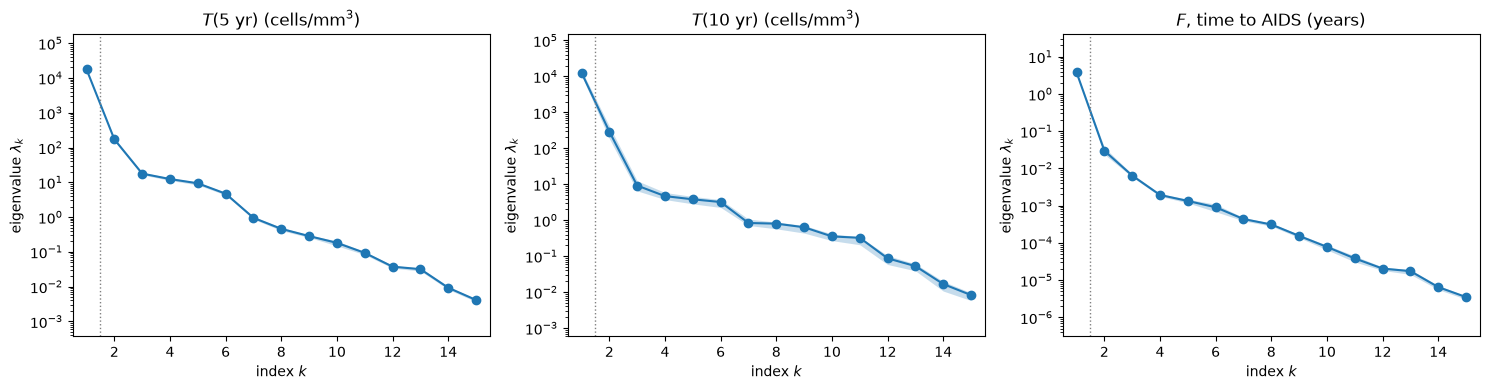

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for q in range(3):
    ac.plotting.plot_eigenvalues(subs[q], ax=axes[q])
    axes[q].set_title(qlabels[q])
fig.tight_layout()
plt.close(fig)
for q in range(3):
    b = subs[q].bootstrap_eigenvalues
    r12 = b[:, 0] / b[:, 1]
    r23 = b[:, 1] / b[:, 2]
    print(f'{hm.QOI_NAMES[q]}: lambda_1 95 % bootstrap interval [{np.percentile(b[:, 0], 2.5):.4g}, {np.percentile(b[:, 0], 97.5):.4g}]; '
          f'lambda_1/lambda_2 2.5-97.5 % [{np.percentile(r12, 2.5):.1f}, {np.percentile(r12, 97.5):.1f}]; '
          f'lambda_2/lambda_3 [{np.percentile(r23, 2.5):.1f}, {np.percentile(r23, 97.5):.1f}]')
fig

For $T(5)$, $\lambda_1 = 1.7675\times10^4$ and $\lambda_1/\lambda_2 = 103$ (94.8–112.1 over the bootstrap replicates), and the first eigenvalue carries 0.9878 of the trace. For $F$, $\lambda_1 = 3.8162$ and $\lambda_1/\lambda_2 = 127.7$ (105.4–156.0), share 0.9892. For $T(10)$, $\lambda_1/\lambda_2 = 43.5$ (33.4–62.3) and $\lambda_2/\lambda_3 = 31.8$ (21.9–43.6): the second ratio is comparable to the first, so $T(10)$ has a well-separated second direction as well. The eigenvalue-gap rule picks $n = 1$ for all three outputs.

T5: bootstrap mean subspace distance, k = 1..4: [0.003 0.017 0.088 0.108]
T10: bootstrap mean subspace distance, k = 1..4: [0.015 0.034 0.186 0.402]
F: bootstrap mean subspace distance, k = 1..4: [0.004 0.038 0.046 0.099]


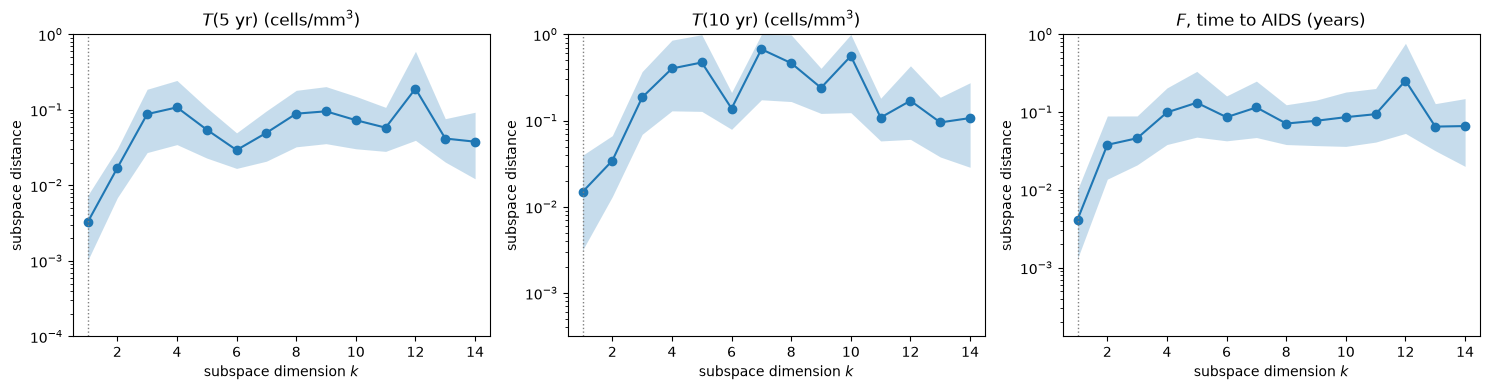

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for q in range(3):
    ac.plotting.plot_subspace_errors(subs[q], ax=axes[q])
    axes[q].set_title(qlabels[q])
fig.tight_layout()
plt.close(fig)
for q in range(3):
    d = subs[q].bootstrap_distances.mean(axis=0)
    print(f'{hm.QOI_NAMES[q]}: bootstrap mean subspace distance, k = 1..4: {np.array2string(d[:4], precision=3)}')
fig

The bootstrap mean distance of the one-dimensional subspace is 0.003 for $T(5)$, 0.015 for $T(10)$ and 0.004 for $F$, so $\mathbf w_1$ is well determined by 1000 samples. For $T(10)$ the two-dimensional subspace is also stable (distance 0.034), consistent with the gap after $\lambda_2$.

**Eigenvectors.** The figure shows $\mathbf w_1$ with its 95 % bootstrap band (blue) and the weights of the paper's Fig. 6 (red squares). The paper gives the weights only as a plot; we read them from the published figure by locating the centre of each marker on a 400-dpi rendering of p. 13 and calibrating with the axis ticks (each read vector has unit norm to within 0.001; reading error about 0.005).

T5: w1 = [-0.153 -0.057 -0.349 -0.122 -0.457 -0.125  0.084  0.446  0.126  0.045
  0.575 -0.039 -0.221  0.02   0.086]
    largest |w1|: deltaV +0.575, pT -0.457, deltaTs +0.446, kT -0.349, rhoM -0.221
    vs Fig. 6: max |difference| 0.023 (cT), cosine 0.9990
T10: w1 = [-0.325 -0.082 -0.158 -0.136 -0.374 -0.142  0.183  0.343  0.257  0.05
  0.476 -0.081 -0.449  0.043  0.165]
    largest |w1|: deltaV +0.476, rhoM -0.449, pT -0.374, deltaTs +0.343, sT -0.325
    vs Fig. 6: max |difference| 0.015 (kT), cosine 0.9996
F: w1 = [-0.273 -0.081 -0.178 -0.153 -0.373 -0.158  0.145  0.361  0.24   0.055
  0.518 -0.07  -0.434  0.035  0.158]
    largest |w1|: deltaV +0.518, rhoM -0.434, pT -0.373, deltaTs +0.361, sT -0.273
    vs Fig. 6: max |difference| 0.085 (rhoM), cosine 0.9921


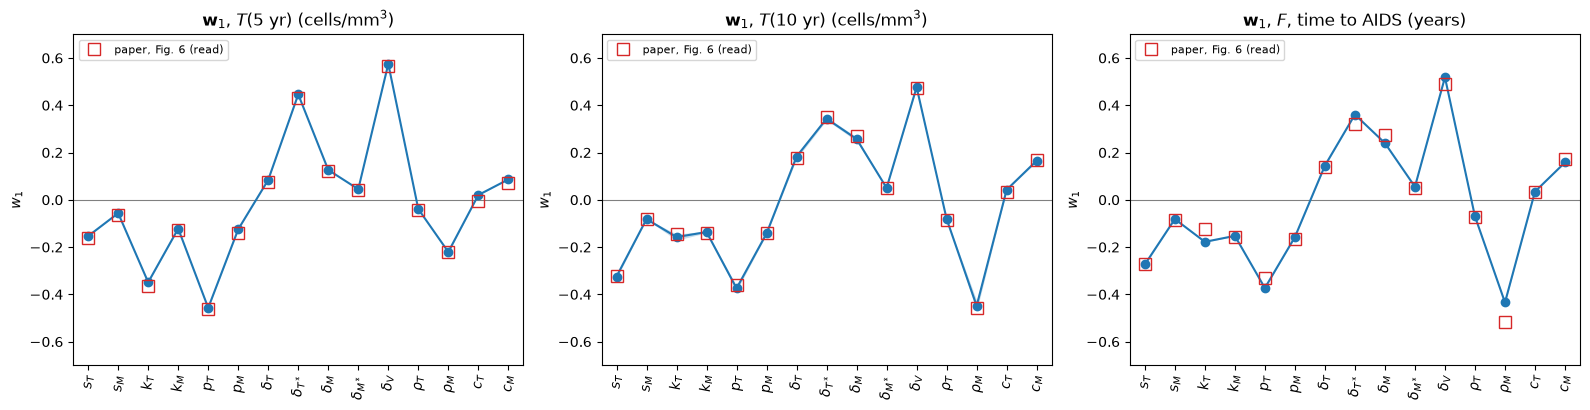

In [9]:
# Fig. 6 (p. 13): first-eigenvector weights read from the published figure by locating the centre of each
# marker in a 400-dpi rendering of the page and calibrating with the axis ticks (reading error about 0.005).
PAPER_W1 = np.array([
    [-0.163, -0.066, -0.365, -0.129, -0.463, -0.140, 0.076, 0.431, 0.121, 0.041, 0.568, -0.045, -0.220, -0.003, 0.071],  # T(5; p), Fig. 6a
    [-0.321, -0.081, -0.143, -0.141, -0.361, -0.140, 0.178, 0.349, 0.270, 0.049, 0.472, -0.084, -0.457, 0.033, 0.168],  # T(10; p), Fig. 6b
    [-0.272, -0.084, -0.125, -0.157, -0.329, -0.164, 0.138, 0.322, 0.274, 0.051, 0.488, -0.072, -0.519, 0.033, 0.174],  # F(p), Fig. 6c
])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for q in range(3):
    ac.plotting.plot_eigenvectors(subs[q], indices=[0], labels=hm.LATEX, interval='percentile', ax=[axes[q]])
    axes[q].plot(np.arange(1, 16), PAPER_W1[q], 's', mfc='none', color='C3', ms=8, label='paper, Fig. 6 (read)')
    axes[q].set_title(r'$\mathbf{w}_1$, ' + qlabels[q])
    axes[q].set_ylim(-0.7, 0.7)
    axes[q].legend(loc='upper left', fontsize=8)
    axes[q].tick_params(axis='x', labelrotation=90)
fig.tight_layout()
plt.close(fig)
for q in range(3):
    w = subs[q].W[:, 0]
    top = np.argsort(-np.abs(w))[:5]
    print(f'{hm.QOI_NAMES[q]}: w1 = {np.array2string(w, precision=3)}')
    print(f'    largest |w1|: ' + ', '.join(f'{hm.NAMES[i]} {w[i]:+.3f}' for i in top))
    print(f'    vs Fig. 6: max |difference| {np.max(np.abs(w - PAPER_W1[q])):.3f} ({hm.NAMES[np.argmax(np.abs(w - PAPER_W1[q]))]}), '
          f'cosine {w @ PAPER_W1[q] / np.linalg.norm(PAPER_W1[q]):.4f}')
fig

The same parameters dominate as in the paper (pp. 12–14). $T(5)$ increases along $\mathbf w_1$ with large weights on $\delta_V$ (+0.575), $p_T$ (−0.457), $\delta_{T^*}$ (+0.446) and $k_T$ (−0.349), the parameters of $R_T$. For $T(10)$ and $F$ the macrophage proliferation rate $\rho_M$ joins them ($-0.449$ and $-0.434$), with $\delta_V$ (+0.476, +0.518), $p_T$ (−0.374, −0.373) and $\delta_{T^*}$ (+0.343, +0.361); more macrophage recruitment means more target cells for the reservoir and an earlier transition to AIDS. Against Fig. 6 the cosines are 0.9990 ($T(5)$), 0.9996 ($T(10)$) and 0.9921 ($F$), with largest differences 0.023 ($c_T$), 0.015 ($k_T$) and 0.085 ($\rho_M$).

**Sufficient summary plots.** Each output against its first active variable $y_1 = \mathbf w_1^T\mathbf x$ (dashed line: the AIDS threshold of 200 cells/mm³).

T5: y1 in [-1.61, 1.62]; corr(y1, f) = 0.9927; Spearman = 0.9970
T10: y1 in [-1.65, 1.58]; corr(y1, f) = 0.6724; Spearman = 0.8653
F: y1 in [-1.64, 1.58]; corr(y1, f) = 0.9825; Spearman = 0.9971


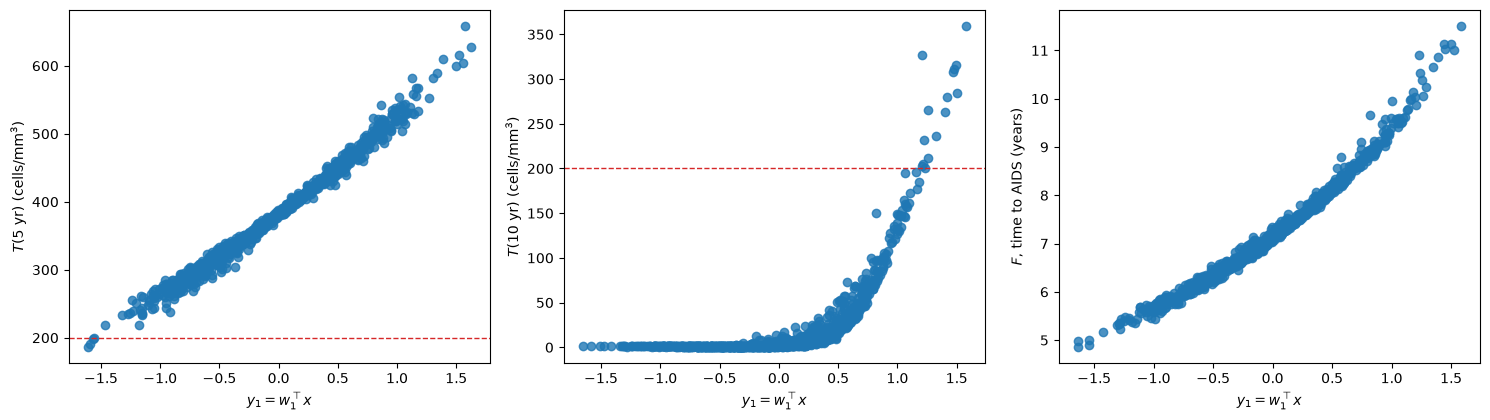

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for q in range(3):
    ac.plotting.plot_sufficient_summary(subs[q], X=X, f=f[:, q], dims=1, qoi_label=qlabels[q], ax=axes[q])
    if q < 2:
        axes[q].axhline(hm.T_AIDS, color='C3', ls='--', lw=1)
fig.tight_layout()
plt.close(fig)
XN = space.to_normalized(X)
for q in range(3):
    y = XN @ subs[q].W[:, 0]
    print(f'{hm.QOI_NAMES[q]}: y1 in [{y.min():.2f}, {y.max():.2f}]; corr(y1, f) = {np.corrcoef(y, f[:, q])[0, 1]:.4f}; '
          f'Spearman = {np.corrcoef(np.argsort(np.argsort(y)), np.argsort(np.argsort(f[:, q])))[0, 1]:.4f}')
fig

$T(5)$ and $F$ are close to linear in $y_1$ (correlation 0.9927 and 0.9825; Spearman 0.9970 and 0.9971). $T(10)$ is strongly nonlinear: it stays near zero for most samples, which have already progressed to AIDS, and rises steeply at the largest $y_1$ (correlation 0.6724, Spearman 0.8653), the hockey-stick shape of the inset of the paper's Fig. 6b. The two-dimensional plots for $T(10)$ and $F$ follow.

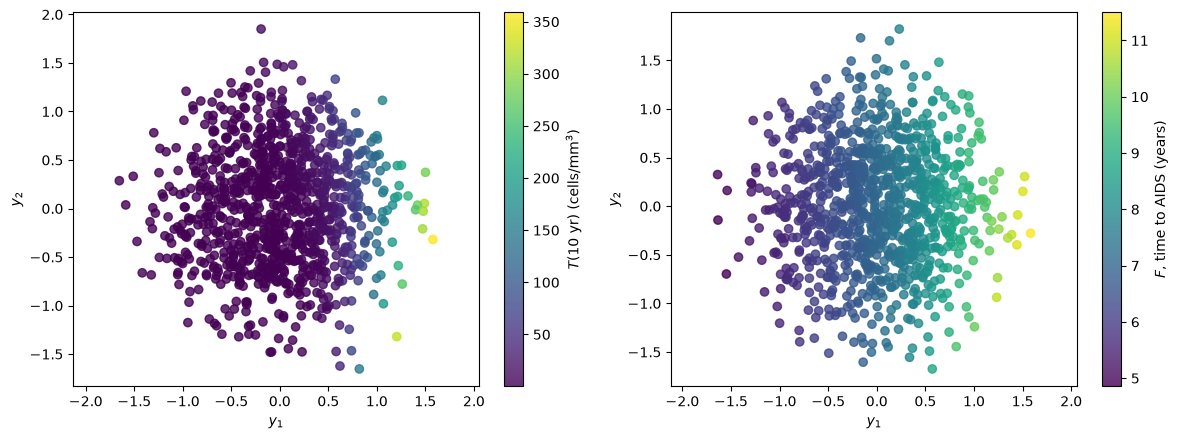

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for k, q in enumerate([1, 2]):
    ac.plotting.plot_sufficient_summary(ac.with_dimension(subs[q], 2), X=X, f=f[:, q], dims=2, qoi_label=qlabels[q], ax=axes[k])
fig.tight_layout()
plt.close(fig)
fig

For $F$ the colour changes along $y_1$ almost only. For $T(10)$ the steep rise at large $y_1$ also depends on $y_2$, which is what the second eigenvalue measures.

#### Surrogates on the active variables

We fit polynomials in $y_1$ (degrees 1, 2, 3 and 5) and a cubic in $(y_1, y_2)$, and report the leave-one-out $R^2$.

T5   LOO R^2  n=1 deg 1: 0.9854; n=1 deg 2: 0.9898; n=1 deg 3: 0.9898; n=1 deg 5: 0.9897; n=2 deg 3: 0.9985
T10  LOO R^2  n=1 deg 1: 0.4465; n=1 deg 2: 0.8435; n=1 deg 3: 0.9594; n=1 deg 5: 0.9668; n=2 deg 3: 0.9720
F    LOO R^2  n=1 deg 1: 0.9649; n=1 deg 2: 0.9915; n=1 deg 3: 0.9929; n=1 deg 5: 0.9929; n=2 deg 3: 0.9979


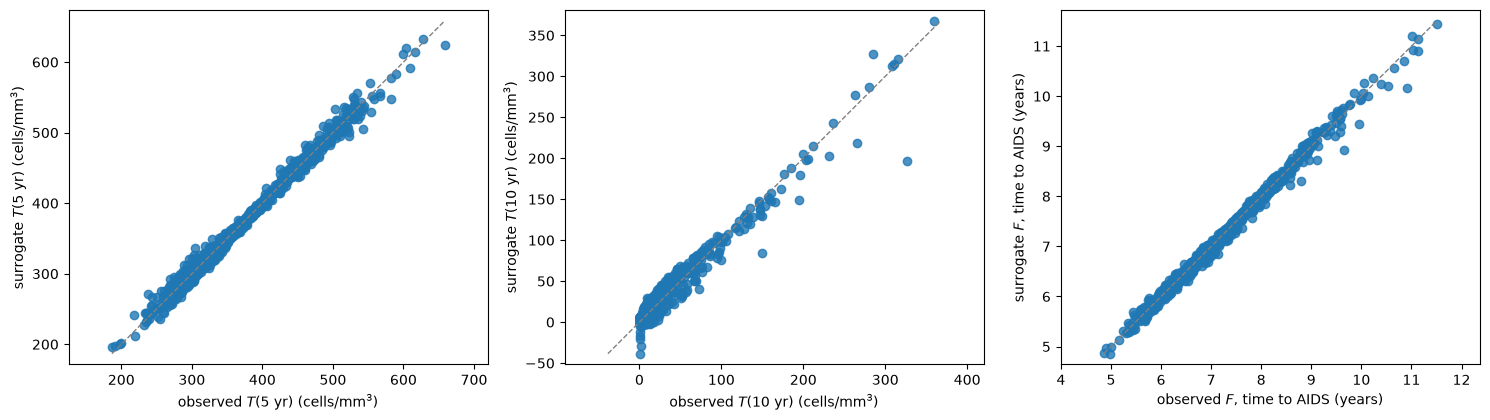

In [12]:
surs = {}
for q in range(3):
    line = []
    for name, nd, deg in [('n=1 deg 1', 1, 1), ('n=1 deg 2', 1, 2), ('n=1 deg 3', 1, 3), ('n=1 deg 5', 1, 5), ('n=2 deg 3', 2, 3)]:
        s = ac.fit_surrogate(X=X, f=f[:, q], subspace=ac.with_dimension(subs[q], nd), kind='poly', degree=deg)
        surs[q, name] = s
        line.append(f'{name}: {s.loo_r_squared:.4f}')
    print(f'{hm.QOI_NAMES[q]:4s} LOO R^2  ' + '; '.join(line))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for q in range(3):
    ac.plotting.plot_surrogate_fit(surs[q, 'n=1 deg 3'], X=X, f=f[:, q], qoi_label=qlabels[q], ax=axes[q])
fig.tight_layout()
plt.close(fig)
fig

A cubic in the single active variable has leave-one-out $R^2 = 0.9898$ for $T(5)$, 0.9594 for $T(10)$ and 0.9929 for $F$. Two active variables raise these to 0.9985, 0.9720 and 0.9979. For $T(10)$ a line in $y_1$ gives only 0.4465, because of the curvature, not because $y_1$ is the wrong direction.

**Choice of dimension.** We use $n = 1$ for all three outputs, as the paper does: $\lambda_1/\lambda_2$ is 103, 43.5 and 127.7 with bootstrap intervals well above 30, the first eigenvalue carries at least 0.975 of the trace, and a cubic in $y_1$ has leave-one-out $R^2 \ge 0.959$. For $T(10)$, $\lambda_2/\lambda_3 = 31.8$ is comparable to $\lambda_1/\lambda_2 = 43.5$, and a second active variable improves the fit (0.9594 to 0.9720), so $n = 2$ is a defensible alternative for that output.

### Comparison with the paper

The paper estimates the active subspaces from about 1000 Monte Carlo samples with one-sided finite-difference gradients (Appendix B, Algorithm steps 1–4, p. 39; step size, seed and solver tolerances not given) and reports only the first eigenvector and the sufficient summary plots (Fig. 6, p. 13). The cell compares the weights in more detail. Our bootstrap measures only our own sampling error; the paper's estimate has its own, so we compare each difference with $\sqrt{2\,\mathrm{sd}^2 + 0.005^2}$, sd being our bootstrap standard deviation of that entry and 0.005 the reading error.

In [13]:
cosTF = subs[1].W[:, 0] @ subs[2].W[:, 0]
cosTF_paper = PAPER_W1[1] @ PAPER_W1[2] / np.linalg.norm(PAPER_W1[1]) / np.linalg.norm(PAPER_W1[2])
print(f'cosine between w1(T10) and w1(F): notebook {cosTF:.4f}, paper Fig. 6 (read) {cosTF_paper:.4f}')
for q in range(3):
    w = subs[q].W[:, 0]
    bv = subs[q].bootstrap_eigenvectors[:, :, 0]          # (nboot, m) sign-aligned replicates of w1
    sd = bv.std(axis=0, ddof=1)
    # the paper's w1 is itself a Monte Carlo estimate from about 1000 samples, so a difference is set against
    # sqrt(2) times our bootstrap sd (two independent estimates of similar size), plus the 0.005 reading error
    z = np.abs(w - PAPER_W1[q]) / np.sqrt(2 * sd**2 + 0.005**2)
    big = np.nonzero(z > 2)[0]
    print(f'{hm.QOI_NAMES[q]}: bootstrap sd of w1 entries {sd.min():.3f}-{sd.max():.3f}; '
          f'|difference| / sqrt(2 sd^2 + 0.005^2) > 2 for {len(big)} of 15' + (': ' if len(big) else '')
          + ', '.join(f'{hm.NAMES[i]} (paper {PAPER_W1[q][i]:+.3f}, notebook {w[i]:+.3f}, ratio {z[i]:.1f})' for i in big))
i5, i8, i11, i13 = 4, 7, 10, 12
for q in range(3):
    w = subs[q].W[:, 0]
    print(f'{hm.QOI_NAMES[q]}: signs pT {w[i5]:+.3f}, deltaTs {w[i8]:+.3f}, deltaV {w[i11]:+.3f}, rhoM {w[i13]:+.3f}')

cosine between w1(T10) and w1(F): notebook 0.9961, paper Fig. 6 (read) 0.9944
T5: bootstrap sd of w1 entries 0.000-0.002; |difference| / sqrt(2 sd^2 + 0.005^2) > 2 for 5 of 15: kT (paper -0.365, notebook -0.349, ratio 3.0), pM (paper -0.140, notebook -0.125, ratio 3.0), deltaTs (paper +0.431, notebook +0.446, ratio 2.9), cT (paper -0.003, notebook +0.020, ratio 4.6), cM (paper +0.071, notebook +0.086, ratio 3.0)
T10: bootstrap sd of w1 entries 0.001-0.012; |difference| / sqrt(2 sd^2 + 0.005^2) > 2 for 0 of 15
F: bootstrap sd of w1 entries 0.000-0.002; |difference| / sqrt(2 sd^2 + 0.005^2) > 2 for 7 of 15: kT (paper -0.125, notebook -0.178, ratio 10.1), pT (paper -0.329, notebook -0.373, ratio 8.2), deltaTs (paper +0.322, notebook +0.361, ratio 7.5), deltaM (paper +0.274, notebook +0.240, ratio 6.7), deltaV (paper +0.488, notebook +0.518, ratio 5.8), rhoM (paper -0.519, notebook -0.434, ratio 13.9), cM (paper +0.174, notebook +0.158, ratio 3.2)
T5: signs pT -0.457, deltaTs +0.446, delta

In [14]:
# Fig. 6c inset (p. 13): F against w^T x along the paper's own F weights, read from the published figure on a
# 600-dpi rendering of p. 13 (frame corners at the ticks -2..2 and 0..10 years; reading error about 0.15 year).
# Centre of the marker band at four values of w^T x; the markers at the top sit at F = 10 for w^T x above about 0.9.
PAPER_F_BAND = {-1.5: 6.0, -0.5: 7.2, 0.0: 7.9, 0.5: 9.1}
wP = PAPER_W1[2] / np.linalg.norm(PAPER_W1[2])
yP = XN @ wP                                              # this data set's samples on the paper's Fig. 6c axis
FF = f[:, 2]
print(f'samples with F >= 10 years: {(FF >= 10).sum()} (largest F {FF.max():.3f}); nominal F {f0[2]:.3f} years at w^T x = 0')
print(' w^T x   paper Fig. 6c (read)   this data set: median F of samples with |w^T x - c| < 0.1 (count)   difference')
for c, fp in PAPER_F_BAND.items():
    m = np.abs(yP - c) < 0.1
    print(f'{c:+5.1f}   {fp:8.1f}               {np.median(FF[m]):8.3f} ({m.sum():3d})                                         {fp - np.median(FF[m]):+.2f}')
# Does a 10-year cap explain the rho_M weight? Cap F at 10 years (gradient zero where F > 10) and re-estimate.
cap = FF > 10
Gcap = G[:, 2].copy()
Gcap[cap] = 0.0
sub_cap = ac.active_subspace(space=space, X=X, f=np.minimum(FF, 10.0), grads=Gcap, estimator='as', nboot=500,
                             rng=SEED, qoi='F capped at 10 years')
sub_cap = ac.orient(sub_cap, by='covariance', X=X, f=np.minimum(FF, 10.0))
wc = sub_cap.W[:, 0]
i_rhoM = hm.NAMES.index('rhoM')
print(f'F capped at 10 years ({cap.sum()} samples capped): lambda_1/lambda_2 = {sub_cap.eigenvalues[0] / sub_cap.eigenvalues[1]:.1f}; '
      f'rhoM weight {wc[i_rhoM]:+.3f} (uncapped {subs[2].W[i_rhoM, 0]:+.3f}, Fig. 6c {PAPER_W1[2][i_rhoM]:+.3f}); '
      f'cosine with Fig. 6c {wc @ wP:.4f} (uncapped {subs[2].W[:, 0] @ wP:.4f}); cosine with uncapped w1 {abs(wc @ subs[2].W[:, 0]):.5f}')
print(f'  capped w1 = {np.array2string(wc, precision=3)}')


samples with F >= 10 years: 15 (largest F 11.505); nominal F 7.105 years at w^T x = 0
 w^T x   paper Fig. 6c (read)   this data set: median F of samples with |w^T x - c| < 0.1 (count)   difference
 -1.5        6.0                  4.981 (  5)                                         +1.02
 -0.5        7.2                  6.334 ( 98)                                         +0.87
 +0.0        7.9                  7.102 (130)                                         +0.80
 +0.5        9.1                  8.078 (100)                                         +1.02


F capped at 10 years (15 samples capped): lambda_1/lambda_2 = 153.5; rhoM weight -0.439 (uncapped -0.434, Fig. 6c -0.519); cosine with Fig. 6c 0.9926 (uncapped 0.9921); cosine with uncapped w1 0.99995
  capped w1 = [-0.268 -0.082 -0.176 -0.155 -0.37  -0.16   0.14   0.36   0.24   0.056
  0.52  -0.069 -0.439  0.034  0.158]


For $T(10)$ every published weight agrees with ours within this combined error. For $T(5)$, five entries differ by 2.9–4.6 times it, though by at most 0.023 in absolute terms. For $F$, seven entries differ by 3.2–13.9 times it: $\rho_M$ (paper −0.519, here −0.434), $k_T$ (−0.125, −0.178), $p_T$ (−0.329, −0.373), $\delta_{T^*}$ (+0.322, +0.361), $\delta_M$, $\delta_V$ and $c_M$. Our sampling error alone cannot explain these differences (bootstrap sd at most 0.002), and the reading of $V(0)$ does not either (the gradient directions for the two readings have cosines of 0.9998 or more at the nominal point). In our results $\mathbf w_1(F)$ is even closer to $\mathbf w_1(T(10))$ (cosine 0.9961) than in the paper's figure (0.9944).

**The paper's $F$ is not the $F$ computed here.** The inset of Fig. 6c (second cell above) differs from this data set in two ways. (1) The paper's $F$ is capped at 10 years: a row of markers sits at $F = 10$ for $\mathbf w^T\mathbf x$ above about 0.9, which matches the 10-year simulation of Fig. 1 (p. 3); here $F$ is uncapped, and 15 samples have $F \ge 10$ (up to 11.505 years). (2) At the same value of the paper's active variable the paper's $F$ is later than ours by +1.02, +0.87, +0.80 and +1.02 years at $\mathbf w^T\mathbf x$ = −1.5, −0.5, 0 and 0.5 (band centres read from the figure, about ±0.15 year, against our medians of 5, 98, 130 and 100 samples within 0.1). At $\mathbf w^T\mathbf x = 0$ the paper's band is at about 7.9 years, while the paper's own nominal run crosses $T = 200$ at about 7.1 years (Fig. 1, read from the curve), as does ours (7.105). So the offset is internal to the paper: Fig. 6c against Fig. 1. The cap does not explain the $\rho_M$ gap: capping $F$ at 10 years here (gradient zero for the 15 capped samples) gives a $\rho_M$ weight of −0.439 (uncapped −0.434, Fig. 6c −0.519) and a cosine of 0.9926 with Fig. 6c (uncapped 0.9921). A different computation of $F$ for Fig. 6c, of which the cap and the offset are the visible signs, is the most concrete candidate cause of the $F$ weight differences, but we cannot reproduce it, and we do not claim that the finite-difference step or the solver tolerances explain them.

| Quantity | Paper value | Notebook value |
|---|---|---|
| Inputs, design | 15 parameters, uniform ±10 % (Table 1, p. 6; App. B, p. 37); $N \approx 1000$ Monte Carlo, forward differences (p. 39) | the same box as printed; $M = 1000$ Monte Carlo (seed 2024), exact sensitivity gradients |
| $R_T$, $R_M$ at nominal | 1.809, 0.09 (p. 10) | 1.8090, 0.0947 |
| Fig. 5 limit with $p_M = 0$ | $T \to 552$, $V \to 283$ (p. 11) | 552.80, 283 |
| Nominal time to AIDS | about 7.1 years (Fig. 1, p. 3, read from the curve) | 7.1052 years |
| Eigenvalues, $\lambda_1/\lambda_2$ | not reported | 103 ($T(5)$), 43.5 ($T(10)$), 127.7 ($F$) |
| Subspace dimension | one-dimensional (Fig. 6, p. 13) | $n = 1$ for all three ($n = 2$ defensible for $T(10)$) |
| Largest weights in $\mathbf w_1(T(5))$ | $p_T$, $\delta_{T^*}$, $\delta_V$ (p. 12); Fig. 6a: −0.463, +0.431, +0.568 | −0.457, +0.446, +0.575 |
| $\rho_M$ weight, $T(5)$; $T(10)$; $F$ | small for $T(5)$, large for $T(10)$ and $F$ (p. 12); Fig. 6: −0.220; −0.457; −0.519 | −0.221; −0.449; −0.434 |
| Cosine of $\mathbf w_1$ with Fig. 6 | — | 0.9990; 0.9996; 0.9921 |
| Weight vectors for $T(10)$ and $F$ | "nearly identical" (p. 13); cosine 0.9944 (Fig. 6, read) | cosine 0.9961 |
| Sign of the $p_T$ weight | text p. 14: $\delta_V$, $\delta_{T^*}$ and $p_T$ "positively correlated"; Fig. 6: negative in all three panels | negative in all three (−0.457, −0.374, −0.373) |
| $T(5) < 200$ | "very few" samples (p. 14, Fig. 6a inset) | 4 of 1000 |
| AIDS within 10 years | "the overwhelming majority" (p. 14, Fig. 6b inset) | 985 of 1000 ($F < 10$) |
| Range of $F$ | "generally linear distribution ranging between 5 and 10 years" (p. 14); Fig. 6c inset capped at 10 years (markers at $F = 10$ for $\mathbf w^T\mathbf x \gtrsim 0.9$) | uncapped: 4.863–11.505 years, 15 samples with $F \ge 10$; close to linear in $y_1$ (correlation 0.9825) |
| $F$ at the same $\mathbf w^T\mathbf x$ (Fig. 6c axis) | about 6.0, 7.2, 7.9, 9.1 years at −1.5, −0.5, 0, 0.5 (Fig. 6c inset, read); nominal crossing about 7.1 years (Fig. 1, p. 3) | medians 4.981, 6.334, 7.102, 8.078 (0.80–1.02 year earlier); nominal 7.105 |
| $\rho_M$ weight of $F$ with $F$ capped at 10 years | −0.519 (Fig. 6c) | −0.439 (uncapped −0.434); cosine with Fig. 6c 0.9926 |

The text on p. 14 lists $p_T$ among the parameters positively correlated with the outputs, but its own Fig. 6 draws a negative weight for $p_T$ in every panel, as we find; more virus production by infected T cells lowers the T-cell count and brings AIDS earlier. We read this as a slip in the text.

### References

[1] C. Clarke and S. Pankavich. [Three-stage modeling of HIV infection and implications for antiretroviral therapy](https://doi.org/10.1007/s00285-024-02056-1). *Journal of Mathematical Biology*, 88(3):34, 2024.

[2] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[3] E. A. Hernandez-Vargas and R. H. Middleton. [Modeling the three stages in HIV infection](https://doi.org/10.1016/j.jtbi.2012.11.028). *Journal of Theoretical Biology*, 320:33–40, 2013.

[4] T. Loudon and S. Pankavich. [Mathematical analysis and dynamic active subspaces for a long term model of HIV](https://doi.org/10.3934/mbe.2017040). *Mathematical Biosciences and Engineering*, 14(3):709–733, 2017.

[R1]: https://doi.org/10.1007/s00285-024-02056-1
[R2]: https://doi.org/10.1137/1.9781611973860
[R3]: https://doi.org/10.1016/j.jtbi.2012.11.028
[R4]: https://doi.org/10.3934/mbe.2017040

### Acknowledgments

From [[1]][R1]: "The second author was supported by the US National Science Foundation under awards DMS-1911145 and DMS-2107938."

In [15]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 29.9 s
